In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('ds_salaries.csv')
df.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')

In [3]:
df.shape

(3755, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           3755 non-null   int64 
 1   experience_level    3755 non-null   object
 2   employment_type     3755 non-null   object
 3   job_title           3755 non-null   object
 4   salary              3755 non-null   int64 
 5   salary_currency     3755 non-null   object
 6   salary_in_usd       3755 non-null   int64 
 7   employee_residence  3755 non-null   object
 8   remote_ratio        3755 non-null   int64 
 9   company_location    3755 non-null   object
 10  company_size        3755 non-null   object
dtypes: int64(4), object(7)
memory usage: 322.8+ KB


In [5]:
df.isnull().sum()

work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1171)

In [7]:
df = df.drop_duplicates()

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['experience_level'] = df['experience_level'].replace('EN', 'Entry-Level')
df['experience_level'] = df['experience_level'].replace('EX', 'Experienced')
df['experience_level'] = df['experience_level'].replace('MI', 'Mid-Level')
df['experience_level'] = df['experience_level'].replace('SE', 'Senior')

In [10]:
df['employment_type'] = df['employment_type'].replace('FT', 'Full-Time')
df['employment_type'] = df['employment_type'].replace('CT', 'Contractor')
df['employment_type'] = df['employment_type'].replace('FL', 'Freelancer')
df['employment_type'] = df['employment_type'].replace('PT', 'Part-Time')

In [11]:
df['company_size'] = df['company_size'].replace('L', "Large")
df['company_size'] = df['company_size'].replace('M', "Medium")
df['company_size'] = df['company_size'].replace('S', "Small")

In [12]:
df.head(10)

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,Senior,Full-Time,Principal Data Scientist,80000,EUR,85847,ES,100,ES,Large
1,2023,Mid-Level,Contractor,ML Engineer,30000,USD,30000,US,100,US,Small
2,2023,Mid-Level,Contractor,ML Engineer,25500,USD,25500,US,100,US,Small
3,2023,Senior,Full-Time,Data Scientist,175000,USD,175000,CA,100,CA,Medium
4,2023,Senior,Full-Time,Data Scientist,120000,USD,120000,CA,100,CA,Medium
5,2023,Senior,Full-Time,Applied Scientist,222200,USD,222200,US,0,US,Large
6,2023,Senior,Full-Time,Applied Scientist,136000,USD,136000,US,0,US,Large
7,2023,Senior,Full-Time,Data Scientist,219000,USD,219000,CA,0,CA,Medium
8,2023,Senior,Full-Time,Data Scientist,141000,USD,141000,CA,0,CA,Medium
9,2023,Senior,Full-Time,Data Scientist,147100,USD,147100,US,0,US,Medium


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

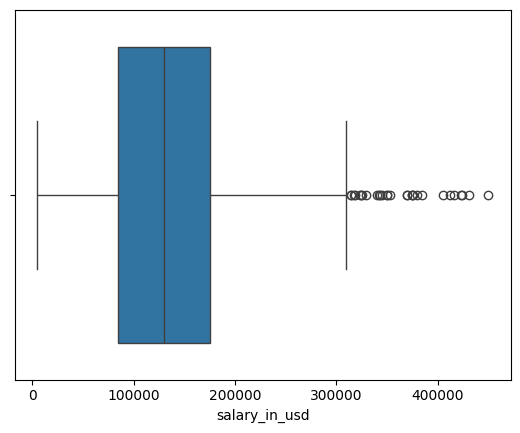

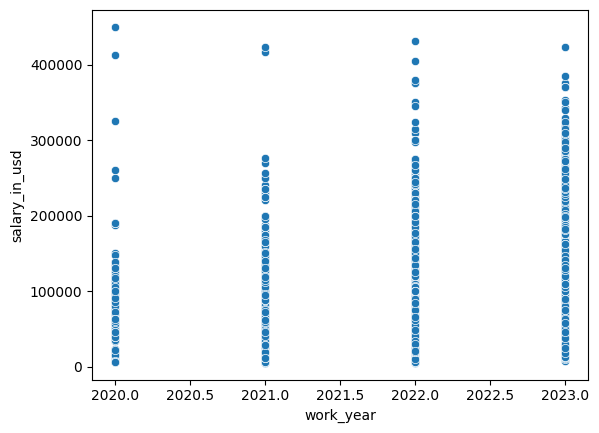

In [14]:
sns.boxplot(x=df['salary_in_usd'])
plt.show()

sns.scatterplot(x=df['work_year'], y=df['salary_in_usd'])
plt.show()

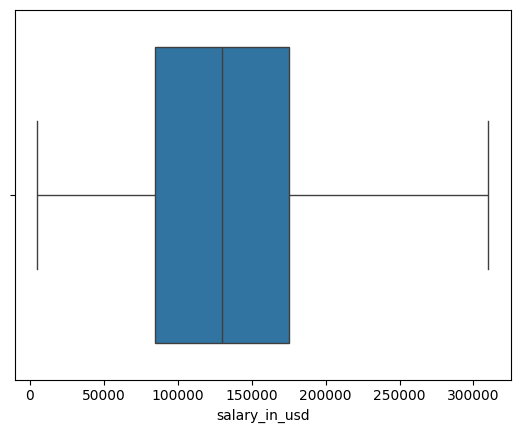

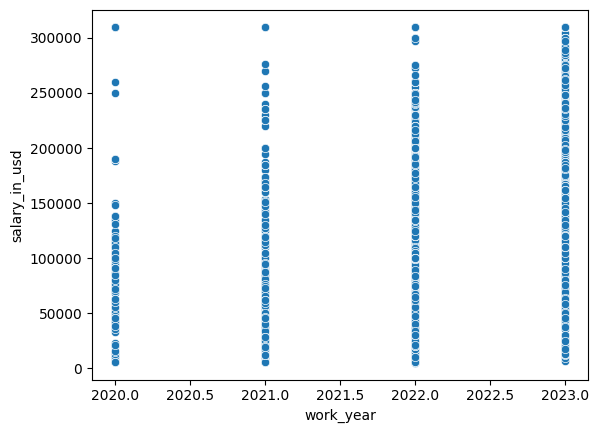

In [15]:
q1 = df['salary_in_usd'].quantile(0.25)
q3 = df['salary_in_usd'].quantile(0.75)
iqr = q3 - q1

# Tính upper bound
upper_bound = q3 + 1.5 * iqr


# Áp dụng Capping
df['salary_in_usd'] = df['salary_in_usd'].clip(upper=upper_bound)


#Vẽ lại boxplot để kiểm tra
sns.boxplot(x=df['salary_in_usd'])
plt.show()

sns.scatterplot(x=df['work_year'], y=df['salary_in_usd'])
plt.show()

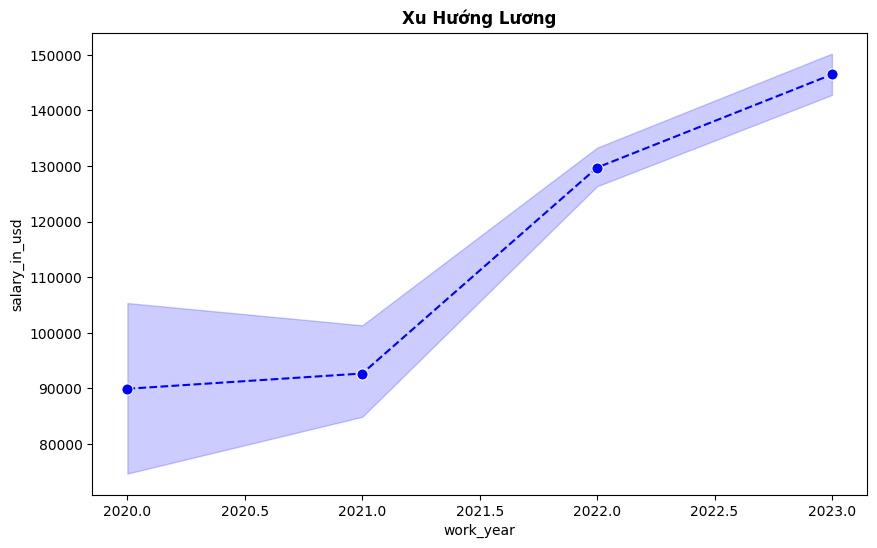

In [16]:
plt.figure(figsize = (10,6))
salary_trend = df[['salary_in_usd', 'work_year']].sort_values(by = 'work_year')
p = sns.lineplot(data=salary_trend, x='work_year', y='salary_in_usd', 
                 marker='o', linestyle='--', color='Blue', markersize=8)
plt.title('Xu Hướng Lương', fontsize=12, fontweight='bold')
p.grid(False)
plt.show()

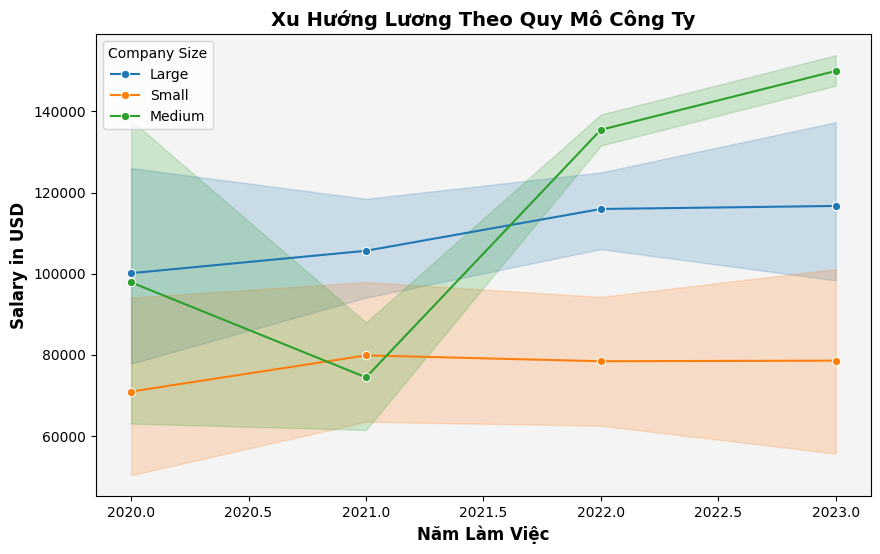

In [17]:
plt.figure(figsize=(10, 6))
p = sns.lineplot(data=df, x='work_year', y='salary_in_usd', hue='company_size', marker='o')

plt.xlabel('Năm Làm Việc', fontsize=12, fontweight='bold')
plt.ylabel('Salary in USD', fontsize=12, fontweight='bold')
plt.legend(title='Company Size', title_fontsize=10, fontsize=10, loc='upper left')
plt.title('Xu Hướng Lương Theo Quy Mô Công Ty', fontsize=14, fontweight='bold')
p.set_facecolor("#f4f4f4")

p.grid(False)
plt.show()

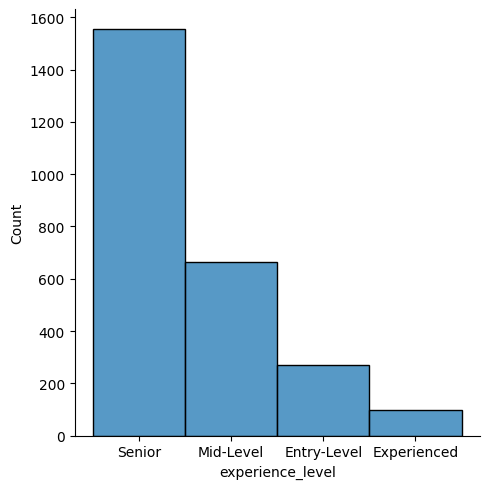

In [18]:
sns.displot(df['experience_level'])

In [19]:
df['company_size'].unique()

array(['Large', 'Small', 'Medium'], dtype=object)

In [20]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,Senior,Full-Time,Principal Data Scientist,80000,EUR,85847.0,ES,100,ES,Large
1,2023,Mid-Level,Contractor,ML Engineer,30000,USD,30000.0,US,100,US,Small
2,2023,Mid-Level,Contractor,ML Engineer,25500,USD,25500.0,US,100,US,Small
3,2023,Senior,Full-Time,Data Scientist,175000,USD,175000.0,CA,100,CA,Medium
4,2023,Senior,Full-Time,Data Scientist,120000,USD,120000.0,CA,100,CA,Medium


<Axes: xlabel='salary_in_usd', ylabel='Count'>

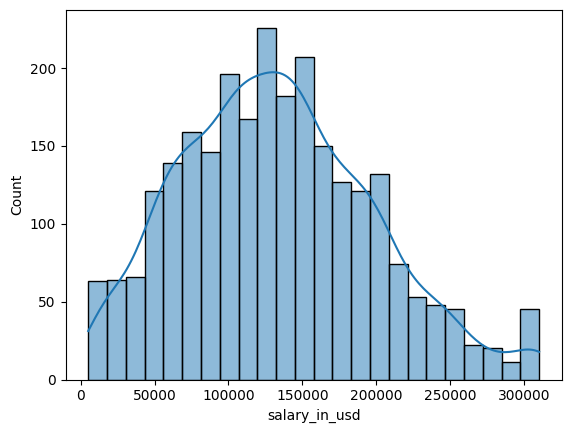

In [21]:
sns.histplot(df['salary_in_usd'], kde=True)

In [22]:
salary_data_jobs_grouped = df.groupby('job_title')['salary_in_usd'].mean()

In [23]:
print(df['remote_ratio'].value_counts())
print(df['remote_ratio'].value_counts(normalize=True) * 100)

remote_ratio
100    1211
0      1186
50      187
Name: count, dtype: int64
remote_ratio
100    46.865325
0      45.897833
50      7.236842
Name: proportion, dtype: float64


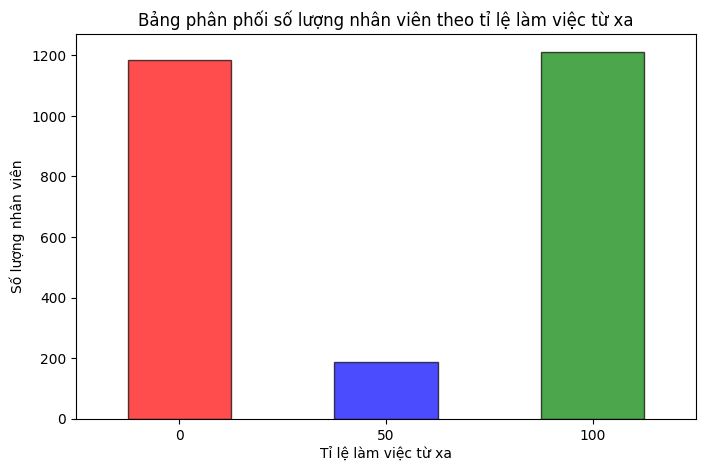

In [24]:
df['remote_ratio'].value_counts().sort_index().plot(
    kind='bar', color=['red', 'blue', 'green'], figsize=(8,5), alpha=0.7, edgecolor='black'
)
plt.xlabel("Tỉ lệ làm việc từ xa")
plt.ylabel("Số lượng nhân viên")
plt.title("Bảng phân phối số lượng nhân viên theo tỉ lệ làm việc từ xa")
plt.xticks(rotation=0)
plt.show()

In [25]:
a = df['job_title'].explode('job_title').nunique()
print("Tổng số lượng việc làm:", a)

Tổng số lượng việc làm: 93


In [26]:
a = df['job_title'].explode().value_counts()
print("Số lần xuất hiện của mỗi job title:")
print(a)

Số lần xuất hiện của mỗi job title:
job_title
Data Engineer                598
Data Scientist               538
Data Analyst                 396
Machine Learning Engineer    206
Analytics Engineer            91
                            ... 
Compliance Data Analyst        1
Deep Learning Researcher       1
Staff Data Analyst             1
Data DevOps Engineer           1
Finance Data Analyst           1
Name: count, Length: 93, dtype: int64


In [27]:
# Lấy 10 công việc có lương cao nhất
top_10_jobs = salary_data_jobs_grouped.sort_values(ascending=False).head(10)

# Chuyển thành chuỗi không có header
output_string = top_10_jobs.to_string(header=False)

# In ra kết quả
print("10 việc làm có mức lương cao nhất: \n", output_string)

10 việc làm có mức lương cao nhất: 
 Data Science Tech Lead                 310037.500000
Cloud Data Architect                   250000.000000
Data Lead                              212500.000000
Principal Data Engineer                192500.000000
Principal Machine Learning Engineer    190000.000000
Director of Data Science               189856.636364
Applied Scientist                      189053.467742
Machine Learning Software Engineer     185923.750000
Principal Data Scientist               184925.812500
Data Science Manager                   181930.173077


In [28]:
df['employment_type'].unique()

array(['Full-Time', 'Contractor', 'Freelancer', 'Part-Time'], dtype=object)

Sử dụng DataFrame với 2584 dòng.

Các giá trị duy nhất trong cột 'employment_type':
['Full-Time' 'Contractor' 'Freelancer' 'Part-Time']

Thống kê lương theo loại hình làm việc:
                  count           mean            std      min       25%  \
employment_type                                                            
Contractor         10.0  102850.650000  104615.990552   7500.0  30117.25   
Freelancer         10.0   51807.800000   29458.879336  12000.0  34281.00   
Full-Time        2547.0  133851.570082   64502.754735   5132.0  85000.00   
Part-Time          17.0   39533.705882   38312.145181   5409.0  12000.00   

                      50%       75%       max  
employment_type                                
Contractor        75000.0  103750.0  310037.5  
Freelancer        50000.0   57500.0  100000.0  
Full-Time        130000.0  175050.0  310037.5  
Part-Time         21669.0   52533.0  125404.0  

Trung vị lương (Median) theo loại hình làm việc:
employment_type
Contractor  

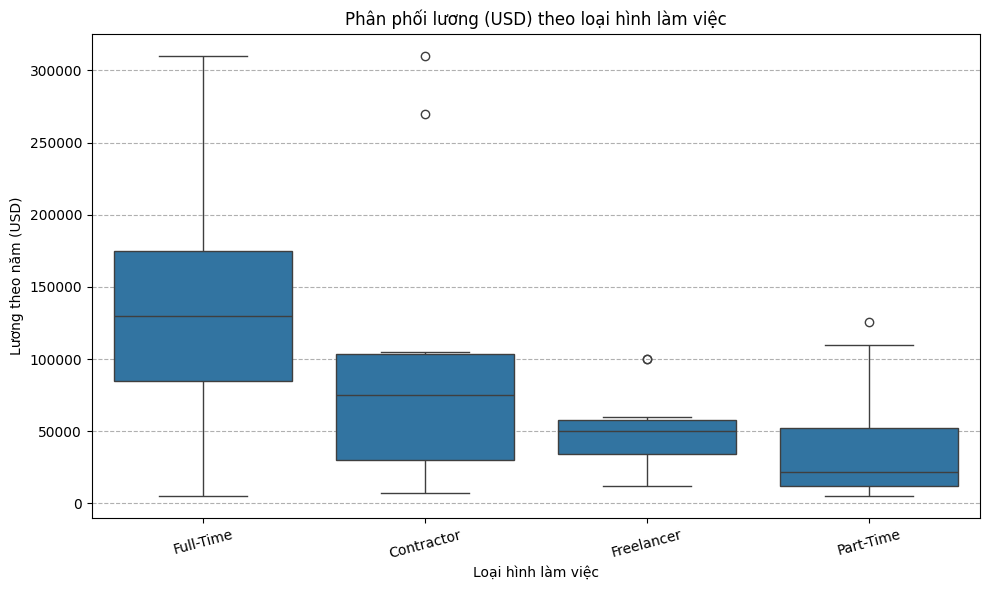

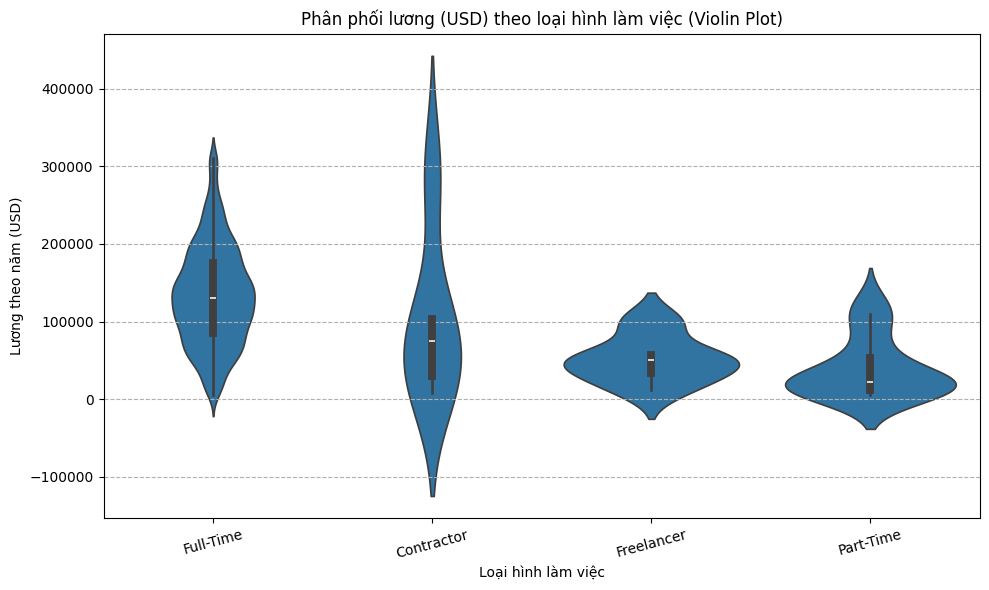

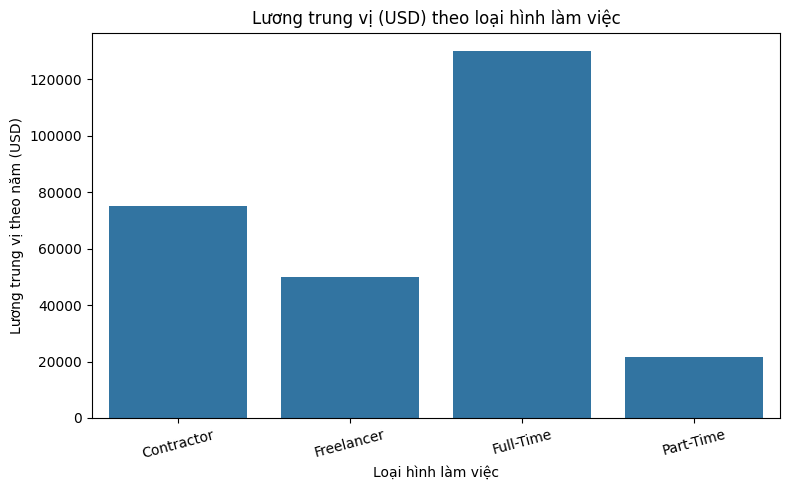

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Chọn DataFrame bạn muốn sử dụng ---
current_df = df.copy()
print(f"Sử dụng DataFrame với {len(current_df)} dòng.")

# 1. Kiểm tra giá trị duy nhất trong cột 'employment_type'
print("\nCác giá trị duy nhất trong cột 'employment_type':")
print(current_df['employment_type'].unique())

# 2. Thống kê mô tả theo nhóm
print("\nThống kê lương theo loại hình làm việc:")
print(current_df.groupby('employment_type')['salary_in_usd'].describe())

print("\nTrung vị lương (Median) theo loại hình làm việc:")
print(current_df.groupby('employment_type')['salary_in_usd'].median())

# 3. Trực quan hóa bằng Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='employment_type', y='salary_in_usd', data=current_df)
plt.title('Phân phối lương (USD) theo loại hình làm việc')
plt.xlabel('Loại hình làm việc')
plt.ylabel('Lương theo năm (USD)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# 4. Trực quan hóa bằng Violin Plot
plt.figure(figsize=(10, 6))
sns.violinplot(x='employment_type', y='salary_in_usd', data=current_df)
plt.title('Phân phối lương (USD) theo loại hình làm việc (Violin Plot)')
plt.xlabel('Loại hình làm việc')
plt.ylabel('Lương theo năm (USD)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# 5. Trực quan hóa bằng Bar Plot (hiển thị trung vị)
median_salaries_employment = current_df.groupby('employment_type')['salary_in_usd'].median()
plt.figure(figsize=(8, 5))
sns.barplot(x=median_salaries_employment.index, y=median_salaries_employment.values)
plt.title('Lương trung vị (USD) theo loại hình làm việc')
plt.xlabel('Loại hình làm việc')
plt.ylabel('Lương trung vị theo năm (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Số lượng dòng trước khi loại bỏ outlier theo employment_type: 2584
Số lượng outliers đã bị xóa dựa trên employment_type: 5
Số lượng dòng còn lại sau khi lọc theo employment_type: 2579

Kiểm tra lại bằng Box Plot sau khi loại bỏ outlier theo employment_type:


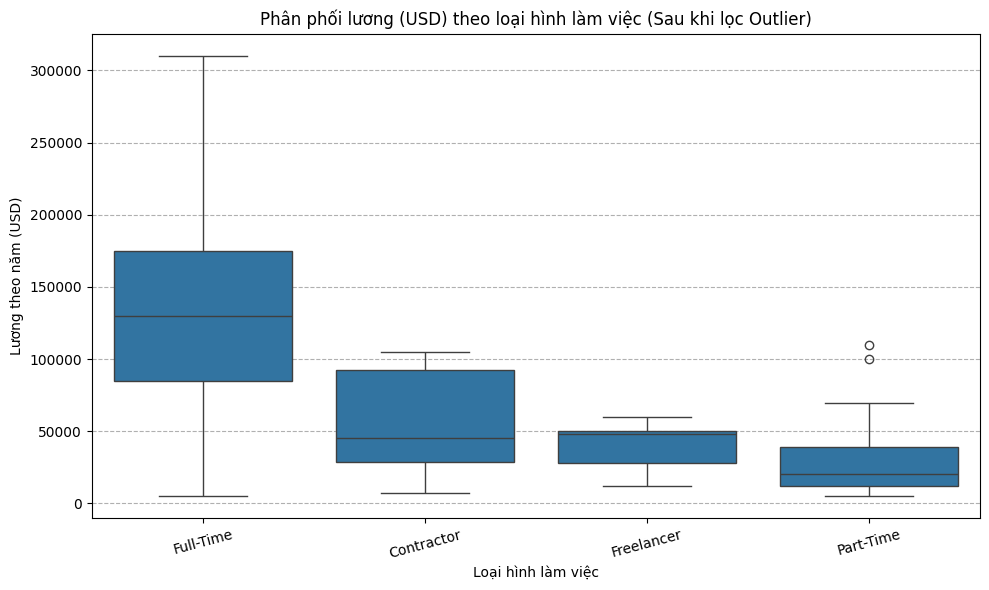

In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- Sử dụng DataFrame đã loại bỏ outlier theo experience_level ---
# current_df = df_no_outliers.copy() # Đã thực hiện ở cell trước
print(f"Số lượng dòng trước khi loại bỏ outlier theo employment_type: {len(current_df)}")

# --- Tính toán Q1, Q3, IQR và Ngưỡng theo employment_type ---
# Sử dụng transform để áp dụng kết quả tính toán theo nhóm cho từng hàng
Q1_emp = current_df.groupby('employment_type')['salary_in_usd'].transform(lambda x: x.quantile(0.25))
Q3_emp = current_df.groupby('employment_type')['salary_in_usd'].transform(lambda x: x.quantile(0.75))
IQR_emp = Q3_emp - Q1_emp

lower_bound_emp = Q1_emp - 1.5 * IQR_emp
upper_bound_emp = Q3_emp + 1.5 * IQR_emp

# --- Lọc bỏ outliers theo employment_type ---
# Tạo điều kiện để giữ lại các hàng không phải outlier
condition_emp = (current_df['salary_in_usd'] >= lower_bound_emp) & \
                (current_df['salary_in_usd'] <= upper_bound_emp)

# Tạo DataFrame mới không chứa outliers theo employment_type
df_no_outliers = current_df[condition_emp].copy() # Sử dụng .copy()

# --- Hiển thị kết quả ---
num_outliers_removed_emp = len(current_df) - len(df_no_outliers)
print(f"Số lượng outliers đã bị xóa dựa trên employment_type: {num_outliers_removed_emp}")
print(f"Số lượng dòng còn lại sau khi lọc theo employment_type: {len(df_no_outliers)}")

# --- (Tùy chọn) Vẽ lại Box Plot để kiểm tra ---
print("\nKiểm tra lại bằng Box Plot sau khi loại bỏ outlier theo employment_type:")
plt.figure(figsize=(10, 6))
# Sử dụng DataFrame mới df_no_outliers_emp
sns.boxplot(x='employment_type', y='salary_in_usd', data=df_no_outliers)
plt.title('Phân phối lương (USD) theo loại hình làm việc (Sau khi lọc Outlier)')
plt.xlabel('Loại hình làm việc')
plt.ylabel('Lương theo năm (USD)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

In [31]:
print(f"Số lượng dòng trước khi loại bỏ outlier theo company_size: {len(df_no_outliers)}")

# Tính Q1, Q3, IQR theo company_size
Q1_comp = df_no_outliers.groupby('company_size')['salary_in_usd'].transform(lambda x: x.quantile(0.25))
Q3_comp = df_no_outliers.groupby('company_size')['salary_in_usd'].transform(lambda x: x.quantile(0.75))
IQR_comp = Q3_comp - Q1_comp

lower_bound_comp = Q1_comp - 1.5 * IQR_comp
upper_bound_comp = Q3_comp + 1.5 * IQR_comp

# Lọc bỏ outlier và tạo DataFrame mới
condition_comp = (df_no_outliers['salary_in_usd'] >= lower_bound_comp) & \
                (df_no_outliers['salary_in_usd'] <= upper_bound_comp)
df_no_outliers_cpm = df_no_outliers[condition_comp].copy()

# Hiển thị kết quả
num_outliers_removed_comp = len(df_no_outliers) - len(df_no_outliers_cpm)
print(f"Số lượng outlier đã bị xóa dựa trên company_size: {num_outliers_removed_comp}")
print(f"Số lượng dòng còn lại sau khi lọc theo company_size: {len(df_no_outliers_cpm)}")

Số lượng dòng trước khi loại bỏ outlier theo company_size: 2579
Số lượng outlier đã bị xóa dựa trên company_size: 37
Số lượng dòng còn lại sau khi lọc theo company_size: 2542


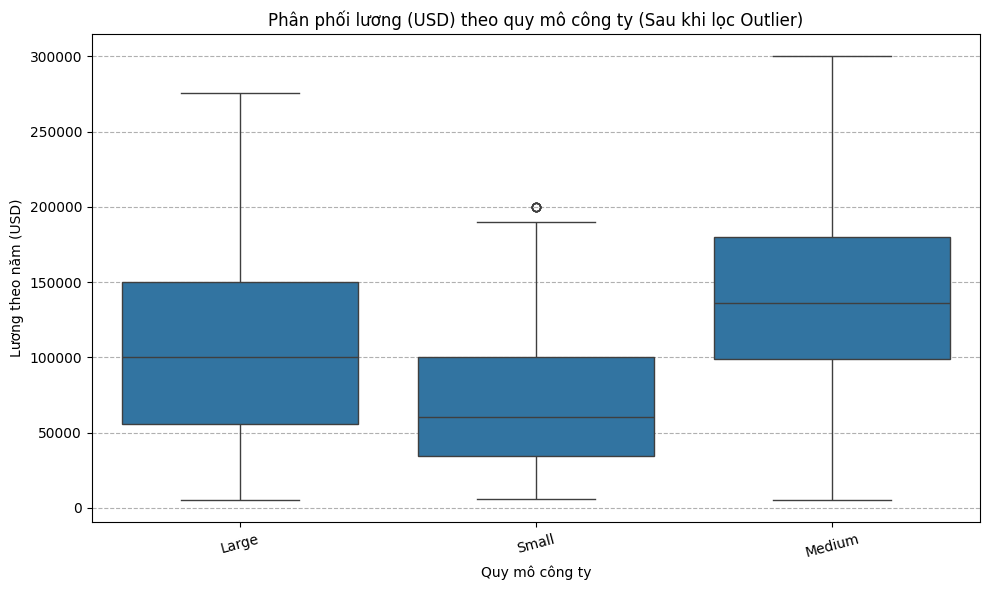

In [32]:
# Vẽ boxplot sau khi lọc outlier theo company_size
plt.figure(figsize=(10, 6))
sns.boxplot(x='company_size', y='salary_in_usd', data=df_no_outliers_cpm)
plt.title('Phân phối lương (USD) theo quy mô công ty (Sau khi lọc Outlier)')
plt.xlabel('Quy mô công ty')
plt.ylabel('Lương theo năm (USD)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

In [33]:
print(f"Số lượng dòng trước khi loại bỏ outlier theo experience_level: {len(df_no_outliers_cpm)}")

# Tính Q1, Q3, IQR theo experience_level
Q1_exp = df_no_outliers_cpm.groupby('experience_level')['salary_in_usd'].transform(lambda x: x.quantile(0.25))
Q3_exp = df_no_outliers_cpm.groupby('experience_level')['salary_in_usd'].transform(lambda x: x.quantile(0.75))
IQR_exp = Q3_exp - Q1_exp

lower_bound_exp = Q1_exp - 1.5 * IQR_exp
upper_bound_exp = Q3_exp + 1.5 * IQR_exp

# Lọc bỏ outlier và tạo DataFrame mới
condition_exp = (df_no_outliers_cpm['salary_in_usd'] >= lower_bound_exp) & \
                (df_no_outliers_cpm['salary_in_usd'] <= upper_bound_exp)
df_no_outliers_final = df_no_outliers_cpm[condition_exp].copy()

# Hiển thị kết quả
num_outliers_removed_exp = len(df_no_outliers_final) - len(df_no_outliers_cpm)
print(f"Số lượng outlier đã bị xóa dựa trên experience_level: {num_outliers_removed_exp}")
print(f"Số lượng dòng còn lại sau khi lọc theo experience_level: {len(df_no_outliers_final)}")

Số lượng dòng trước khi loại bỏ outlier theo experience_level: 2542
Số lượng outlier đã bị xóa dựa trên experience_level: -16
Số lượng dòng còn lại sau khi lọc theo experience_level: 2526


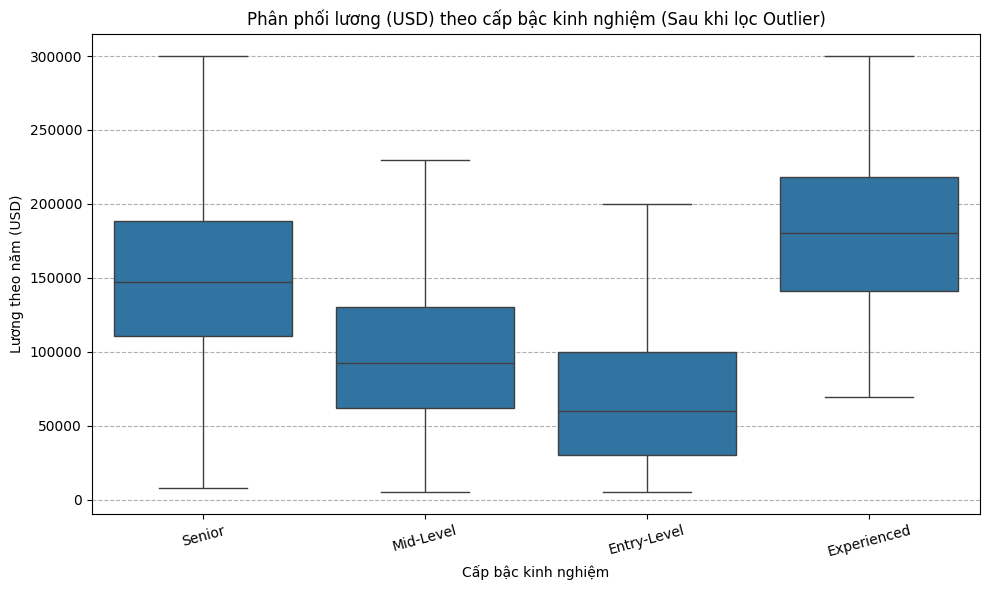

In [34]:
# Vẽ boxplot sau khi lọc outlier theo experience_level
plt.figure(figsize=(10, 6))
sns.boxplot(x='experience_level', y='salary_in_usd', data=df_no_outliers_final)
plt.title('Phân phối lương (USD) theo cấp bậc kinh nghiệm (Sau khi lọc Outlier)')
plt.xlabel('Cấp bậc kinh nghiệm')
plt.ylabel('Lương theo năm (USD)')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

In [35]:

# Tóm tắt theo cấp bậc kinh nghiệm
exp_stats = df_no_outliers_final.groupby('experience_level')['salary_in_usd'].agg(['mean', 'min', 'max']).reset_index()
exp_salary = pd.DataFrame({
    'Factor': exp_stats['experience_level'],
    'Average Salary (USD)': exp_stats['mean'].round(0).astype(int),
    'Notes': 'Range: $' + exp_stats['min'].round(0).astype(str) + ' - $' + exp_stats['max'].round(0).astype(str)
})

# Tóm tắt theo quy mô công ty
comp_stats = df_no_outliers_final.groupby('company_size')['salary_in_usd'].agg(['mean', 'min', 'max']).reset_index()
comp_salary = pd.DataFrame({
    'Factor': comp_stats['company_size'],
    'Average Salary (USD)': comp_stats['mean'].round(0).astype(int),
    'Notes': 'Range: $' + comp_stats['min'].round(0).astype(str) + ' - $' + comp_stats['max'].round(0).astype(str)
})

# Tóm tắt theo tỷ lệ làm việc từ xa
remote_stats = df_no_outliers_final.groupby('remote_ratio')['salary_in_usd'].agg(['mean', 'min', 'max']).reset_index()
remote_salary = pd.DataFrame({
    'Factor': remote_stats['remote_ratio'].map({0: '0% Remote', 50: '50% Remote', 100: '100% Remote'}),
    'Average Salary (USD)': remote_stats['mean'].round(0).astype(int),
    'Notes': 'Range: $' + remote_stats['min'].round(0).astype(str) + ' - $' + remote_stats['max'].round(0).astype(str)
})

# Kết hợp tất cả
summary_table = pd.concat([exp_salary, comp_salary, remote_salary])
print("\nTóm tắt từ DataFrame cuối cùng sau khi lọc toàn bộ outlier:")
print(summary_table)


Tóm tắt từ DataFrame cuối cùng sau khi lọc toàn bộ outlier:
        Factor  Average Salary (USD)                        Notes
0  Entry-Level                 67469   Range: $5409.0 - $200000.0
1  Experienced                179847  Range: $69741.0 - $300000.0
2    Mid-Level                 97721   Range: $5132.0 - $230000.0
3       Senior                150795   Range: $8000.0 - $300240.0
0        Large                103980   Range: $5409.0 - $276000.0
1       Medium                138700   Range: $5132.0 - $300240.0
2        Small                 71740   Range: $5679.0 - $200000.0
0    0% Remote                139759   Range: $5882.0 - $300240.0
1   50% Remote                 71733   Range: $5409.0 - $250000.0
2  100% Remote                128432   Range: $5132.0 - $300000.0


In [49]:
df_no_outliers_final

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,Senior,Full-Time,Principal Data Scientist,80000,EUR,85847.0,ES,100,ES,Large
1,2023,Mid-Level,Contractor,ML Engineer,30000,USD,30000.0,US,100,US,Small
2,2023,Mid-Level,Contractor,ML Engineer,25500,USD,25500.0,US,100,US,Small
3,2023,Senior,Full-Time,Data Scientist,175000,USD,175000.0,CA,100,CA,Medium
4,2023,Senior,Full-Time,Data Scientist,120000,USD,120000.0,CA,100,CA,Medium
...,...,...,...,...,...,...,...,...,...,...,...
3749,2021,Senior,Full-Time,Data Specialist,165000,USD,165000.0,US,100,US,Large
3751,2021,Mid-Level,Full-Time,Principal Data Scientist,151000,USD,151000.0,US,100,US,Large
3752,2020,Entry-Level,Full-Time,Data Scientist,105000,USD,105000.0,US,100,US,Small
3753,2020,Entry-Level,Contractor,Business Data Analyst,100000,USD,100000.0,US,100,US,Large


In [38]:
features = ['experience_level', 'work_year', 'company_location', 'employee_residence', 'salary_currency']

X = df_no_outliers_final[features]
y = df_no_outliers_final['salary_in_usd']

In [39]:
# 2. Mã hóa các biến phân loại
le_dict = {}
for column in X.columns:
    if X[column].dtype == 'object':
        le = LabelEncoder()
        X[column] = le.fit_transform(X[column])
        le_dict[column] = le

/var/folders/09/5j1zr3z17nn8bzd1c6v50fyr0000gn/T/ipykernel_26961/533093730.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = le.fit_transform(X[column])
/var/folders/09/5j1zr3z17nn8bzd1c6v50fyr0000gn/T/ipykernel_26961/533093730.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[column] = le.fit_transform(X[column])
/var/folders/09/5j1zr3z17nn8bzd1c6v50fyr0000gn/T/ipykernel_26961/533093730.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try u

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, 
                                                    random_state=42)

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

def find_best_rf_params(X, y):
    """
    Tìm cấu hình tốt nhất cho Random Forest bằng GridSearchCV.
    
    Parameters:
    X (pd.DataFrame): Dữ liệu huấn luyện (features).
    y (pd.Series): Nhãn tương ứng.
    
    Returns:
    dict: Bộ tham số tối ưu.
    """
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt', 'log2'] 
    }
    
    rf = RandomForestRegressor(random_state=42)
    grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, n_jobs=-1, verbose=2)
    grid_search.fit(X, y)
    
    return grid_search.best_params_

best_params = find_best_rf_params(X_train, y_train)
print("Tham số tốt nhất cho Random Forest:", best_params)


Fitting 3 folds for each of 324 candidates, totalling 972 fits
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.1s
[CV] END max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=5, n_e

In [42]:
rf_model = RandomForestRegressor(n_estimators=100, 
                                random_state=42,
                                max_depth=10,
                                min_samples_split=10,
                                min_samples_leaf=1)
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_split=10, random_state=42)

In [43]:
y_pred = rf_model.predict(X_test)

In [44]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Đánh giá mô hình Random Forest:")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-squared Score: {r2:.4f}")

Đánh giá mô hình Random Forest:
Root Mean Squared Error (RMSE): $44428.29
R-squared Score: 0.4241


In [45]:
joblib.dump(rf_model, 'random_forest_salary_model.pkl')
joblib.dump(le_dict, 'label_encoders.pkl')

print("\nMô hình đã được lưu vào file 'random_forest_salary_model.pkl'")
print("Các LabelEncoders đã được lưu vào file 'label_encoders.pkl'")


Mô hình đã được lưu vào file 'random_forest_salary_model.pkl'
Các LabelEncoders đã được lưu vào file 'label_encoders.pkl'


In [46]:
# 8. Ví dụ cách sử dụng mô hình để dự đoán
# Tạo một mẫu dữ liệu mới
new_data = pd.DataFrame({
    'work_year': [2023],
    'experience_level': ['Senior'],
    'employment_type': ['Full-Time'],
    'job_title': ['Data Scientist'],
    'employee_residence': ['US'],
    'remote_ratio': [100],
    'company_location': ['US'],
    'company_size': ['Large']
})

# Mã hóa dữ liệu mới
for column in new_data.columns:
    if column in le_dict:
        new_data[column] = le_dict[column].transform(new_data[column])

# Dự đoán
prediction = rf_model.predict(new_data)
print(f"\nDự đoán lương cho mẫu dữ liệu mới: ${prediction[0]:.2f}")

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- company_size
- employment_type
- job_title
- remote_ratio
Feature names seen at fit time, yet now missing:
- salary_currency
